# M2b: validation checks

Contract: `audit/contracts/M2_shared_specific.md` (M2b). Definitions: `audit/validation_plan.md`, plus the user's
"M2b checks" decisions (`audit/decisions.md`, M2 section). Logic: `src/m2b_validation.py`.
Numbers and plots only; the one pass mark is V9 (> 70% of the paper's DE genes recovered).
DE calls are re-derived with the current rule (q < 0.05 and |log2FC| ≥ 1, `m1b_de.classify`); the number of calls that
differ from the files is printed.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats

from src import m2b_validation as v
from src.figures import CT_COLORS, DONOR_ORDER, STACK_ORDER

pd.set_option("display.width", 160, "display.max_columns", 30)
PROC, FIG = ROOT / "data/processed", ROOT / "figures"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.axisbelow": True, "figure.dpi": 110})

de, n_changed = v.rederive(pd.read_csv(PROC / "m1b_de.csv"))
assert (de["run"] == "main").all() and not de.duplicated(["cell_type", "gene"]).any()
print(f"main-run calls changed by the >= rule: {n_changed}")
fits = pd.read_csv(PROC / "m1b_fits.csv")
runs, n_changed_runs = v.read_runs(PROC / "m1b_runs.csv", ["shuffle_", "lodo_", "unpaired", "no_outliers"])
print(f"other-run calls changed by the >= rule: {n_changed_runs}")
ifna = v.ifna_genes(de["gene"].unique())
counts = pd.read_csv(PROC / "m1a_counts.csv", index_col="gene")
samples = pd.read_csv(PROC / "m1a_samples.csv")
print(f"main run: {len(de)} rows; other runs read: {runs['run'].nunique()}; Hallmark IFN-α genes: {len(ifna)}; "
      f"pseudobulk: {counts.shape[0]} genes × {counts.shape[1]} samples")


def save(df, name):
    df.to_csv(PROC / f"m2_validation_{name}.csv", index=False)
    print(f"m2_validation_{name}.csv: {df.shape}")

main-run calls changed by the >= rule: 0


other-run calls changed by the >= rule: 0


main run: 125608 rows; other runs read: 45; Hallmark IFN-α genes: 97; pseudobulk: 15701 genes × 128 samples


## P1: canonical ISGs DE per cell type

gene,ISG15,IFI6,IFIT1,IFIT2,IFIT3,MX1,OAS1,RSAD2,IRF7,STAT1,n_de
cell_type,,,,,,,,,,,
B cells,up,up,up,up,up,up,up,up,up,up,10
CD14+ Monocytes,up,up,up,up,up,up,up,up,up,up,10
CD4 T cells,up,up,up,up,up,up,up,up,up,up,10
CD8 T cells,up,up,up,up,up,up,up,up,up,up,10
Dendritic cells,up,up,up,up,up,up,up,up,up,up,10
FCGR3A+ Monocytes,up,up,up,up,up,up,up,up,up,up,10
Megakaryocytes,up,up,up,up,up,up,up,up,none,none,8
NK cells,up,up,up,up,up,up,up,up,up,up,10


m2_validation_p1_isgs.csv: (8, 12)


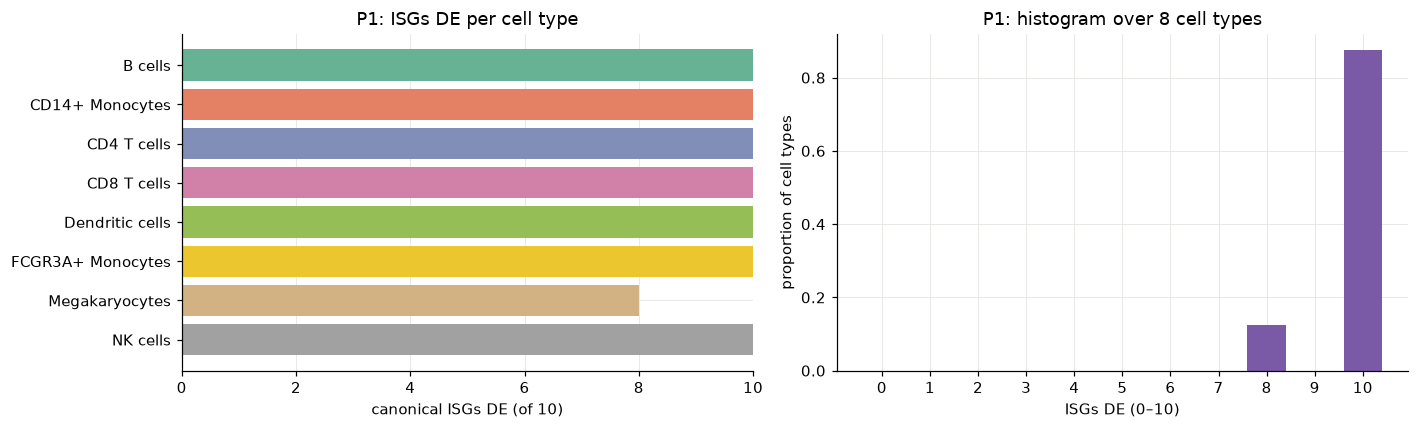

In [2]:
p1 = v.p1_isgs(de).loc[STACK_ORDER]
display(p1)
save(p1.reset_index(), "p1_isgs")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].barh(p1.index, p1["n_de"], color=[CT_COLORS[c] for c in p1.index])
axes[0].set(xlim=(0, 10), xlabel="canonical ISGs DE (of 10)", title="P1: ISGs DE per cell type"); axes[0].invert_yaxis()
hist = p1["n_de"].value_counts(normalize=True).reindex(range(11), fill_value=0)
axes[1].bar(hist.index, hist.values, color="#7a5aa6")
axes[1].set(xticks=range(11), xlabel="ISGs DE (0–10)", ylabel="proportion of cell types", title="P1: histogram over 8 cell types")
plt.tight_layout(); fig.savefig(FIG / "m2b_p1_isgs.png", dpi=200, bbox_inches="tight"); plt.show()

## P2 / P3: Fisher tests on Hallmark IFN-α
P2: up-DEGs vs all tested genes (baseMean > 1) in that cell type. P3: up-DEGs vs down-DEGs. `inf` odds ratio = no IFN gene among the down-DEGs.
Headline: one-sided ("greater") p, BH-adjusted across the 8 cell types (`p2_q_bh`). Two-sided p shown for reference.

In [3]:
fisher = v.p2_p3_fisher(de, ifna).set_index("cell_type").loc[STACK_ORDER].reset_index()
display(fisher)
save(fisher, "p2_p3_fisher")

,cell_type,n_tested,n_ifna_tested,n_up,up_ifna,n_down,down_ifna,p2_odds_ratio,p2_p_greater,p2_q_bh,p2_p_two_sided,p3_odds_ratio,p3_p_greater,p3_p_two_sided
0,B cells,7064,90,344,72,89,0,98.558824,2.841526e-80,1.136610e-79,2.841526e-80,inf,1.110955e-08,1.389063e-08
1,CD14+ Monocytes,8802,93,1219,84,1116,1,62.282526,1.679863e-62,2.239817e-62,1.679863e-62,82.519824,2.009079e-23,3.654062e-23
2,CD4 T cells,9735,92,378,78,105,0,173.512857,1.930407e-98,1.544326e-97,1.930407e-98,inf,6.922659e-10,8.672830e-10
3,CD8 T cells,5351,82,159,56,10,0,108.026886,6.423905e-70,1.284781e-69,6.423905e-70,inf,1.555170e-02,3.162745e-02
4,Dendritic cells,5227,89,272,65,52,0,64.515902,1.591816e-66,2.546906e-66,1.591816e-66,inf,2.726458e-06,5.024825e-06
5,FCGR3A+ Monocytes,6606,93,600,74,319,1,44.330398,6.613290e-61,7.558046e-61,6.613290e-61,44.737643,1.073992e-13,1.350494e-13
6,Megakaryocytes,2688,72,23,14,4,0,69.919540,1.781730e-17,1.781730e-17,1.781730e-17,inf,4.074074e-02,4.074074e-02
7,NK cells,6108,88,217,63,40,0,95.989091,9.533832e-75,2.542355e-74,9.533832e-75,inf,4.243024e-06,5.198774e-06


m2_validation_p2_p3_fisher.csv: (8, 14)


## P4: expression-matched null
Per cell type: control mean = mean DESeq2-normalised count over the kept control samples (median-of-ratios size
factors over all kept samples and all genes; equal to R `estimateSizeFactorsForMatrix` on Megakaryocytes to 6 decimals);
detection = fraction of the cell type's control cells from kept donors with count > 0. Each up-DEG gets the 30 nearest
tested genes on rank-percentiles of the two (Euclidean), focal excluded; 1,000 draws of one gene per up-DEG, no gene
reused within a draw (next-nearest unused gene if a pool runs out); statistic = IFN-α genes in the matched set;
p = (1 + #null ≥ observed) / 1,001; seed 0 (one generator per cell type). Diagnostics: % of null genes that are DEGs,
% that are IFN-α, % of up-DEGs that are IFN-α.

,cell_type,n_ctrl_cells,n_tested,n_up,observed,null_mean,null_median,null_max,p_empirical,pct_null_genes_de,pct_null_genes_ifna,pct_degs_ifna,n_pool_exhausted
0,B cells,1306,7064,344,72,6.884,7.0,15,0.001,9.0163,2.0012,20.9302,0
1,CD14+ Monocytes,2770,8802,1219,84,15.116,15.0,25,0.001,32.3249,1.2400,6.8909,112
2,CD4 T cells,5154,9735,378,78,4.645,5.0,12,0.001,8.3720,1.2288,20.6349,0
3,CD8 T cells,1082,5351,159,56,4.293,4.0,12,0.001,4.6226,2.7000,35.2201,0
4,Dendritic cells,186,5227,272,65,10.792,11.0,21,0.001,12.4904,3.9676,23.8971,0
5,FCGR3A+ Monocytes,736,6606,600,74,13.059,13.0,23,0.001,20.9160,2.1765,12.3333,0
6,Megakaryocytes,66,2688,23,14,3.940,4.0,9,0.001,7.7043,17.1304,60.8696,0
7,NK cells,915,6108,217,63,4.900,5.0,13,0.001,6.6217,2.2581,29.0323,0


m2_validation_p4_matched_null.csv: (8, 13)


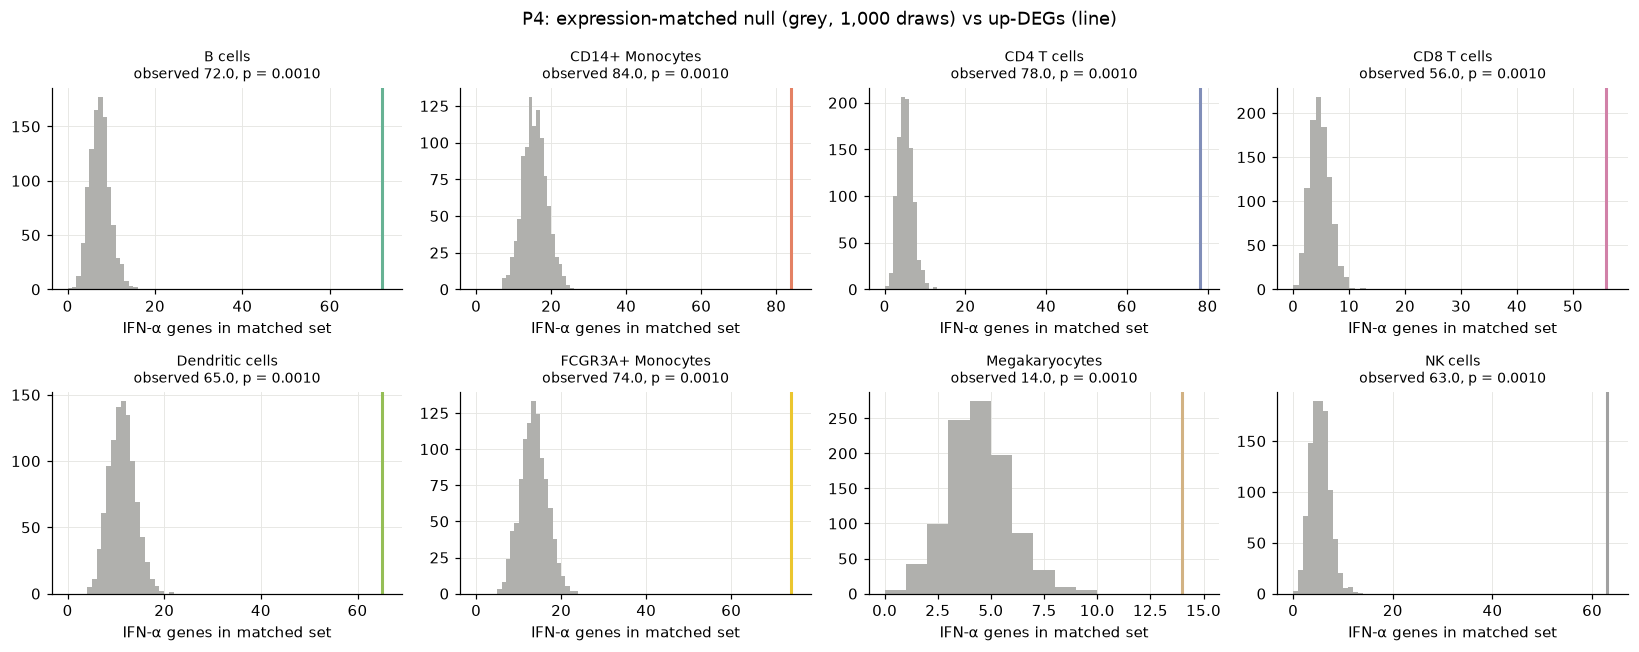

In [4]:
adata = ad.read_h5ad(PROC / "m0_cells.h5ad")
assert counts.index.equals(adata.var_names)
p4_rows, p4_draws = [], {}
for ct in STACK_ORDER:
    s_ct = samples[samples["cell_type"] == ct]
    donors = s_ct.loc[s_ct["kept"], "donor"].unique()
    cells = ((adata.obs["cell_type"] == ct) & (adata.obs["condition"] == "ctrl") & adata.obs["donor"].isin(donors)).to_numpy()
    detection = pd.Series(np.asarray((adata.X[cells] > 0).mean(axis=0)).ravel(), index=adata.var_names)
    d_ct = de[de["cell_type"] == ct]
    feats = v.p4_features(counts, s_ct, d_ct.loc[d_ct["tested"], "gene"], detection)
    res, null = v.p4_null(feats, d_ct.loc[d_ct["de"] == "up", "gene"], d_ct.loc[d_ct["de"] != "none", "gene"], ifna,
                          k=30, n_draws=1000, seed=0)
    p4_rows.append({"cell_type": ct, "n_ctrl_cells": int(cells.sum()), "n_tested": len(feats), **res})
    p4_draws[ct] = null
p4 = pd.DataFrame(p4_rows)
display(p4.round(4))
save(p4, "p4_matched_null")

fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, ct in zip(axes.flat, STACK_ORDER):
    r = p4.set_index("cell_type").loc[ct]
    ax.hist(p4_draws[ct], bins=range(int(max(p4_draws[ct].max(), r["observed"])) + 2), color="#b0b0ad")
    ax.axvline(r["observed"], c=CT_COLORS[ct], lw=2)
    ax.set_title(f"{ct}\nobserved {r['observed']}, p = {r['p_empirical']:.4f}", fontsize=9)
    ax.set_xlabel("IFN-α genes in matched set")
fig.suptitle("P4: expression-matched null (grey, 1,000 draws) vs up-DEGs (line)")
plt.tight_layout(); fig.savefig(FIG / "m2b_p4_null.png", dpi=200, bbox_inches="tight"); plt.show()

## N1: label shuffles (35 / 10 / 3) next to the real DE count

m2_validation_n1_shuffles.csv: (231, 4)


min           max         size        
kind               real shuffle  real shuffle real shuffle
cell_type                                                 
B cells             433       0   433       2    1      35
CD14+ Monocytes    2335       0  2335       1    1      35
CD4 T cells         483       0   483       0    1      35
CD8 T cells         169       0   169       0    1      35
Dendritic cells     324       0   324       0    1      10
FCGR3A+ Monocytes   919       0   919       0    1      35
Megakaryocytes       27       0    27       0    1       3
NK cells            257       0   257       0    1      35

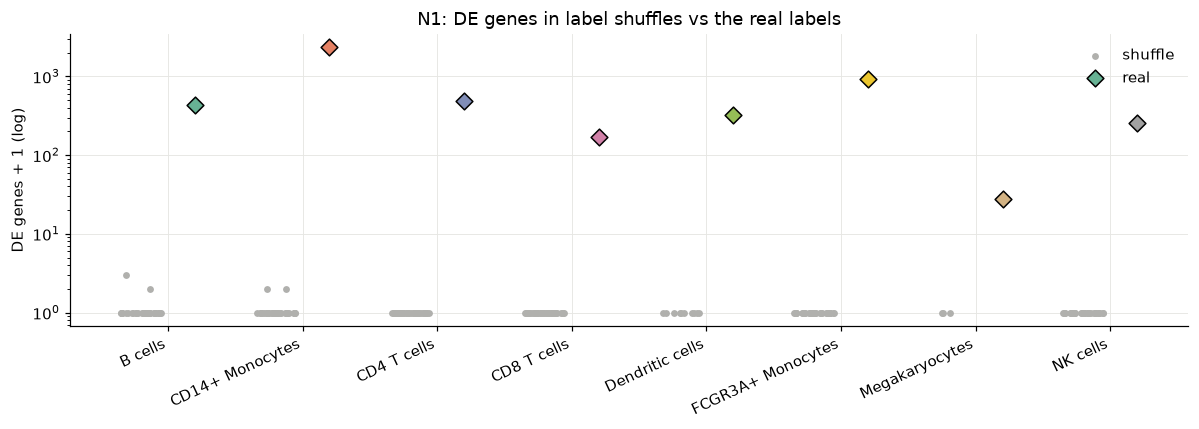

In [5]:
n1 = v.n1_counts(runs[runs["run"].str.startswith("shuffle_")], fits, de)
save(n1, "n1_shuffles")
display(n1.pivot_table(index="cell_type", columns="kind", values="n_de", aggfunc=["min", "max", "size"]).loc[STACK_ORDER])

fig, ax = plt.subplots(figsize=(11, 4))
for i, ct in enumerate(STACK_ORDER):
    s = n1[(n1["cell_type"] == ct) & (n1["kind"] == "shuffle")]["n_de"]
    ax.scatter(i + np.random.default_rng(i).uniform(-0.15, 0.15, len(s)) - 0.2, s + 1, s=12, c="#b0b0ad",
               label="shuffle" if i == 0 else None)
    real = n1[(n1["cell_type"] == ct) & (n1["kind"] == "real")]["n_de"].iloc[0]
    ax.scatter(i + 0.2, real + 1, s=60, marker="D", c=CT_COLORS[ct], edgecolor="k", label="real labels (colour = cell type)" if i == 0 else None)
ax.set_yscale("log"); ax.set_xticks(range(8), STACK_ORDER, rotation=25, ha="right")
ax.set(ylabel="DE genes + 1 (log scale)", title="N1: DE genes in label shuffles vs the real labels")
leg = ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1)); leg.legend_handles[1].set_facecolor("white"); plt.tight_layout(); fig.savefig(FIG / "m2b_n1_shuffles.png", dpi=200, bbox_inches="tight"); plt.show()

## R1: leave-one-donor-out direction stability (O4: log2FC keeps its sign in every refit; significance not required)

In [6]:
r1, r1_calls = v.r1_lodo(de, runs[runs["run"].str.startswith("lodo_")])
r1 = r1.set_index("cell_type").loc[STACK_ORDER].reset_index()
display(r1)
save(r1, "r1_lodo")

,cell_type,n_lodo_runs,n_de,n_stable,pct_stable
0,B cells,8,433,433,100.0
1,CD14+ Monocytes,8,2335,2335,100.0
2,CD4 T cells,8,483,483,100.0
3,CD8 T cells,8,169,169,100.0
4,Dendritic cells,6,324,324,100.0
5,FCGR3A+ Monocytes,8,919,919,100.0
6,Megakaryocytes,4,27,27,100.0
7,NK cells,8,257,257,100.0


m2_validation_r1_lodo.csv: (8, 5)


## R2 / R3: overlap of main DE calls with the unpaired (`~ condition`) and no-outlier runs
Genes, either direction; `sign_flips` = DE in both runs with opposite directions.

,cell_type,n_main,n_other,n_both,jaccard,pct_main_recovered,sign_flips,other_run
0,B cells,433,491,428,0.862903,98.845266,0,unpaired
1,CD14+ Monocytes,2335,2465,2271,0.897983,97.259101,0,unpaired
2,CD4 T cells,483,481,464,0.928000,96.066253,0,unpaired
3,CD8 T cells,169,168,154,0.841530,91.124260,0,unpaired
4,Dendritic cells,324,472,319,0.668763,98.456790,0,unpaired
5,FCGR3A+ Monocytes,919,1086,885,0.790179,96.300326,0,unpaired
6,Megakaryocytes,27,45,24,0.500000,88.888889,0,unpaired
7,NK cells,257,289,247,0.826087,96.108949,0,unpaired
8,B cells,433,455,417,0.885350,96.304850,0,no_outliers
9,CD14+ Monocytes,2335,2341,2328,0.991482,99.700214,0,no_outliers


m2_validation_r2_r3_overlap.csv: (16, 8)


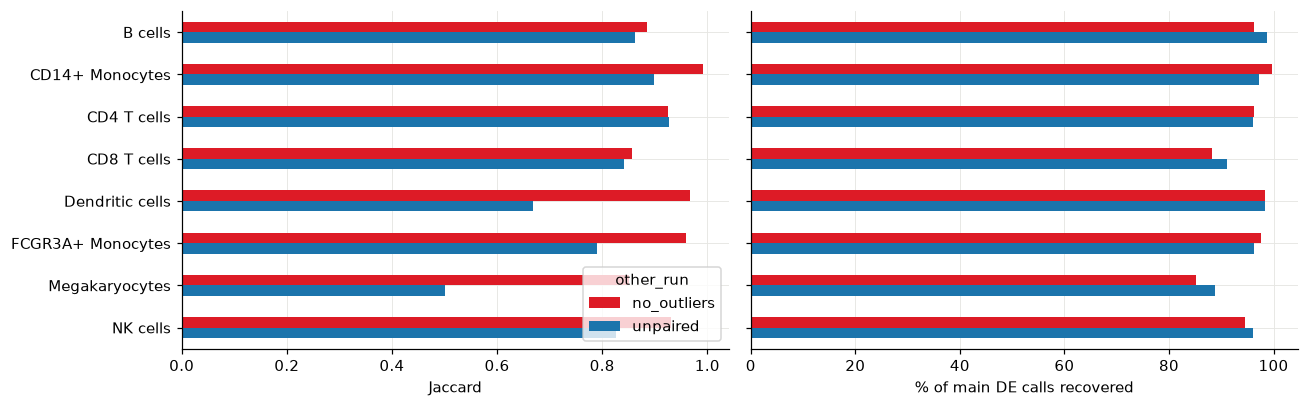

In [7]:
r23 = pd.concat([v.overlap(de, runs[runs["run"] == name], name).rename(columns={f"n_{name}": "n_other"}).assign(other_run=name)
                 for name in ["unpaired", "no_outliers"]], ignore_index=True)
display(r23)
save(r23, "r2_r3_overlap")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, col, lab in [(axes[0], "jaccard", "Jaccard"), (axes[1], "pct_main_recovered", "% of main DE calls recovered")]:
    w = r23.pivot(index="cell_type", columns="other_run", values=col).loc[STACK_ORDER]
    w.plot.barh(ax=ax, color={"unpaired": "#1b74ac", "no_outliers": "#dd1b26"}, legend=False)
    ax.set(xlabel=lab, ylabel="")
axes[1].legend(*axes[0].get_legend_handles_labels(), title="other run", frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
axes[0].invert_yaxis(); plt.tight_layout(); fig.savefig(FIG / "m2b_r2_r3.png", dpi=200, bbox_inches="tight"); plt.show()

## V9 / V9b: Kang 2018 Supp Table 1
V9 overlap is the M1b computation (same symbol mapping), restated. Correlations on two gene sets, leading with
`paper_tested` = every paper DE gene we tested; `in_both` = DE in both lists. `median_abs_diff` is there because a
correlation cannot see shrinkage toward 0. Decision: calls stay on unshrunk log2FC; V9b is recorded as favouring
shrunken values.

,cell_type,ours_only,in_both,paper_only,opposite_sign,pct_paper_recovered,pct_ours_in_paper,V9
0,B cells,28,405,178,0,69.5,93.5,fail
1,CD14+ Monocytes,426,1909,342,0,84.8,81.8,pass
2,CD4 T cells,54,429,108,0,79.9,88.8,pass
3,CD8 T cells,20,149,99,0,60.1,88.2,fail
4,Dendritic cells,17,307,274,0,52.8,94.8,fail
5,FCGR3A+ Monocytes,98,821,400,0,67.2,89.3,fail
6,Megakaryocytes,1,26,81,0,24.3,96.3,fail
7,NK cells,23,234,117,0,66.7,91.1,fail


,cell_type,gene_set,n,pearson_unshrunk,spearman_unshrunk,median_abs_diff_unshrunk,pearson_shrunk,spearman_shrunk,median_abs_diff_shrunk
0,B cells,paper_tested,572,0.994,0.984,0.137,0.991,0.978,0.106
1,CD14+ Monocytes,paper_tested,2135,0.988,0.976,0.165,0.987,0.975,0.129
2,CD4 T cells,paper_tested,520,0.986,0.976,0.152,0.989,0.975,0.074
3,CD8 T cells,paper_tested,228,0.983,0.963,0.196,0.970,0.935,0.242
4,Dendritic cells,paper_tested,574,0.988,0.980,0.194,0.986,0.977,0.192
5,FCGR3A+ Monocytes,paper_tested,1155,0.991,0.977,0.156,0.991,0.975,0.121
6,Megakaryocytes,paper_tested,105,0.920,0.906,0.542,0.841,0.771,0.507
7,NK cells,paper_tested,336,0.991,0.980,0.159,0.984,0.960,0.123
8,B cells,in_both,405,0.995,0.989,0.138,0.993,0.990,0.089
9,CD14+ Monocytes,in_both,1909,0.990,0.981,0.162,0.990,0.982,0.121


m2_validation_v9_overlap.csv: (8, 8)
m2_validation_v9_correlation.csv: (16, 9)


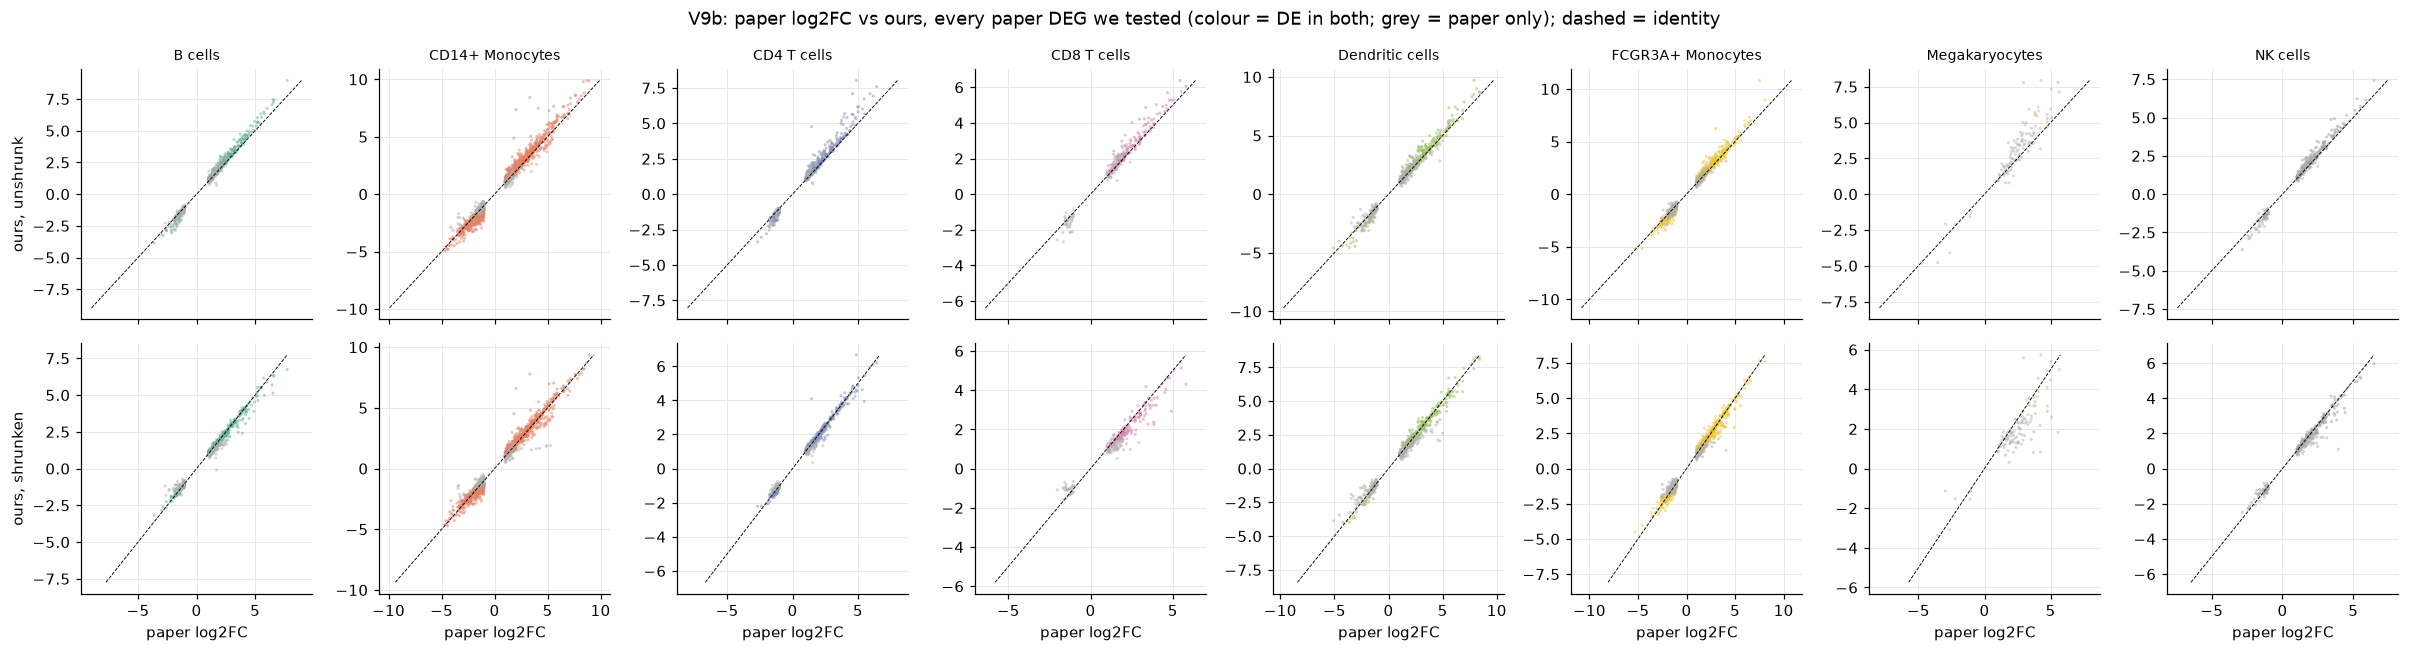

In [8]:
paper = v.paper_supp1()
v9_overlap, v9_cor, v9_genes = v.v9(de, paper)
v9_overlap = v9_overlap.set_index("cell_type").loc[STACK_ORDER].reset_index()
v9_cor = v9_cor.sort_values(["gene_set", "cell_type"], ascending=[False, True], key=lambda c: c if c.name == "gene_set"
                            else c.map(STACK_ORDER.index)).reset_index(drop=True)
display(v9_overlap); display(v9_cor.round(3))
save(v9_overlap, "v9_overlap"); save(v9_cor, "v9_correlation")

fig, axes = plt.subplots(2, 8, figsize=(22, 6), sharex="col")
for j, ct in enumerate(STACK_ORDER):
    g = v9_genes[(v9_genes["cell_type"] == ct) & v9_genes["tested"]]
    for i, (col, lab) in enumerate([("log2FC", "ours, unshrunk"), ("log2FC_shrunk", "ours, shrunken")]):
        ax = axes[i, j]
        ax.scatter(g["paper_log2FC"], g[col], s=4, alpha=0.5, lw=0, c=np.where(g["in_both"], CT_COLORS[ct], "#b0b0ad"))
        lim = np.nanmax(np.abs(g[["paper_log2FC", col]].to_numpy()))
        ax.plot([-lim, lim], [-lim, lim], "k--", lw=0.6)
        ax.set_title(ct if i == 0 else "", fontsize=9); ax.set_ylabel(lab if j == 0 else "")
        ax.set_xlabel("paper log2FC" if i == 1 else "")
fig.suptitle("V9b: paper log2FC vs ours, every paper DEG we tested (colour = DE in both; grey = paper only); dashed = identity")
plt.tight_layout(); fig.savefig(FIG / "m2b_v9b_scatter.png", dpi=150, bbox_inches="tight"); plt.show()

## F3b: Kang Fig 3b recreated
log2(CPM + 1) per donor × cell type × condition, all 128 samples (incl. the 12 dropped by A1, as the paper's 8 donors
per group) plus all PBMCs (sum over all cells per donor × condition); genes DE in ≥ 1 cell type; rows z-scored (ddof 0).
Rows in the authors' file order (their 7 modules); our DE genes absent from it are at the bottom as "no module".
The authors' file values are not log2 CPM (0–43,088, many ties), so this recreates the layout, not their values.

module,6,1,2,3,4,5,0
genes,877,521,469,401,398,380,9


Label '3' has 401 genes = Supp Table 2 'Cluster III' (401 genes); other label-to-numeral matches are not established.
F3b matrix: 2801 genes × 144 samples; genes per authors' module:


module,6,1,no module,2,3,4,5,0
genes,605,487,438,378,357,274,256,6


m2_validation_f3b_zscores.csv: (2801, 146)


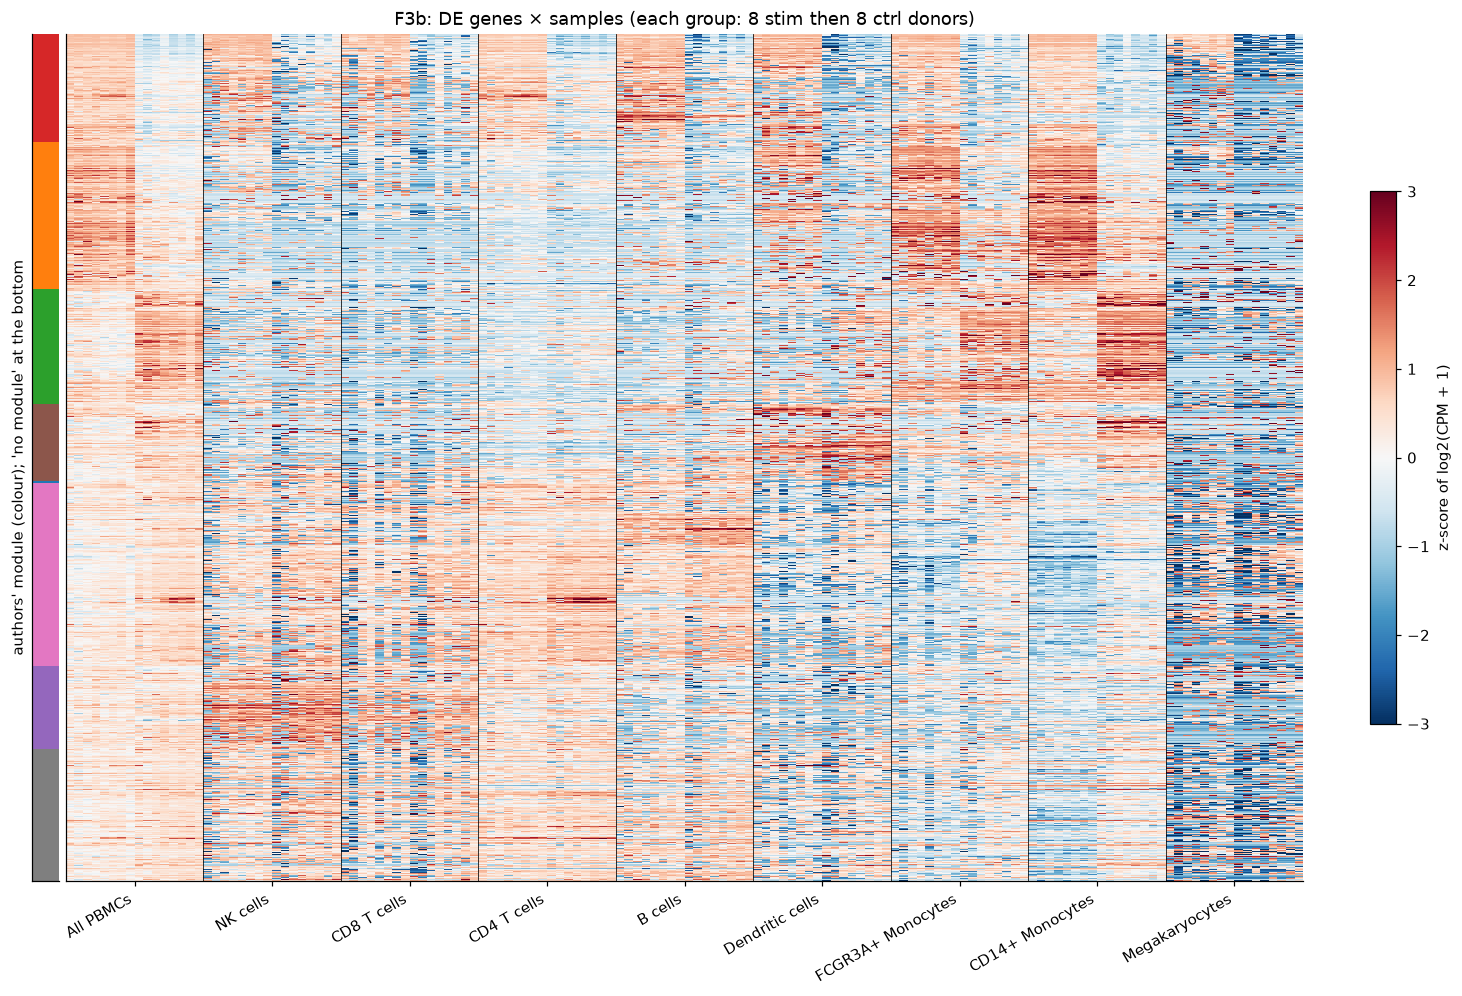

In [9]:
authors = v.authors_modules(paper)
display(authors["module"].value_counts().rename("genes").to_frame().T)
print("Label '3' has 401 genes = Supp Table 2 'Cluster III' (401 genes); other label-to-numeral matches are not established.")

de_genes = sorted(de.loc[de["de"] != "none", "gene"].unique())
z = v.f3b_matrix(counts, samples, de_genes, pseudocount=1, use_dropped_samples=True)
amod = authors.set_index("gene")
row_mod = amod["module"].reindex(z.index).where(z.index.isin(amod.index), "no module")
rows = amod["row_order"].reindex(z.index).where(z.index.isin(amod.index), len(amod)).sort_values(kind="stable").index
GROUPS = ["All PBMCs", "NK cells", "CD8 T cells", "CD4 T cells", "B cells", "Dendritic cells", "FCGR3A+ Monocytes",
          "CD14+ Monocytes", "Megakaryocytes"]  # authors' column order
cols = [f"{g}|{d}|{c}" for g in GROUPS for c in ["ctrl", "stim"] for d in DONOR_ORDER]
assert set(cols) == set(z.columns) and len(cols) == 144
zf = z.loc[rows, cols]
print(f"F3b matrix: {zf.shape[0]} genes × {zf.shape[1]} samples; genes per authors' module:")
display(row_mod.value_counts().rename("genes").to_frame().T)
save(zf.rename_axis("gene").reset_index().assign(authors_module=row_mod[rows].to_numpy()), "f3b_zscores")

fig, (axm, ax) = plt.subplots(1, 2, figsize=(16, 10), gridspec_kw={"width_ratios": [0.4, 20], "wspace": 0.01})
mods = sorted(row_mod.unique())
axm.imshow(row_mod[rows].map({m: i for i, m in enumerate(mods)}).to_numpy()[:, None], aspect="auto", cmap="tab10",
           vmin=0, vmax=9, interpolation="nearest")
axm.set(xticks=[], yticks=[], ylabel="authors' module (colour); 'no module' at the bottom")
im = ax.imshow(zf.to_numpy(), aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3, interpolation="nearest")
ax.set_xticks([i * 16 + 7.5 for i in range(9)], GROUPS, rotation=30, ha="right"); ax.set_yticks([])
for i in range(1, 9):
    ax.axvline(i * 16 - 0.5, c="k", lw=0.5)
ax.grid(False); axm.grid(False)
fig.colorbar(im, ax=ax, fraction=0.02, anchor=(0.0, 1.0), shrink=0.5, label="z-score of log2(CPM + 1)")
handles = [plt.matplotlib.patches.Patch(color=plt.cm.tab10(i), label=f"{m} ({(row_mod == m).sum():,} genes)")
           for i, m in enumerate(mods)]
ax.legend(handles=handles, title="authors' module label\n(3 = Supp Table 2 Cluster III)", frameon=False,
          loc="lower left", bbox_to_anchor=(1.01, 0.0), fontsize=9, title_fontsize=9)
ax.set_title("F3b: DE genes × samples (each group: 8 ctrl then 8 stim donors)")
fig.savefig(FIG / "m2b_f3b_heatmap.png", dpi=150, bbox_inches="tight"); plt.show()

## Modules: our k-means (k = 7, random_state 0, n_init 25) vs the authors' 7 clusters ("method inferred")
k-means on all rows of the F3b matrix; the ARI uses genes that have an authors' module.

In [10]:
ours, xtab, ari = v.compare_modules(zf, authors, k=7, random_state=0, n_init=25)
xtab_all = pd.crosstab(ours, row_mod[ours.index])
display(xtab_all)
print(f"adjusted Rand index (genes in both): {ari:.3f}  (n = {int(xtab.to_numpy().sum())})")
save(xtab_all.reset_index(), "modules_overlap")
save(pd.DataFrame({"gene": ours.index, "our_module": ours.to_numpy(), "authors_module": row_mod[ours.index].to_numpy()}),
     "modules_genes")

module,0,1,2,3,4,5,6,no module
our_module,,,,,,,,
0,0,356,52,9,3,63,3,23
1,0,0,0,4,35,13,313,201
2,1,1,225,0,1,63,0,25
3,4,84,5,177,47,50,82,46
4,0,1,0,5,115,2,55,41
5,1,3,92,2,66,64,143,102
6,0,42,4,160,7,1,9,0


adjusted Rand index (genes in both): 0.329  (n = 2363)
m2_validation_modules_overlap.csv: (7, 9)
m2_validation_modules_genes.csv: (2801, 3)


## Module biology: KEGG legacy (O5) enrichment of our modules
One-sided Fisher per KEGG set, background = genes tested in ≥ 1 cell type, BH across sets within each module.
KEGG symbols get the 6 B4 renames (e.g. RIGI → DDX58).
KEGG legacy has no Influenza A, Measles, Herpes simplex or Hepatitis C sets (added to KEGG after the legacy freeze),
so Supp Table 2's Cluster III can only be compared on terms present in both.

In [11]:
kegg = v.kegg_sets()
universe = set(de.loc[de["tested"], "gene"])
kegg_genes = set().union(*kegg.values())
print(f"KEGG legacy: {len(kegg)} sets, {len(kegg_genes)} genes; {len(kegg_genes & universe)} in the background "
      f"({len(universe)} genes); {len(kegg_genes & set(counts.index))} in the data at all")
kres = pd.concat([v.kegg_enrichment(ours.index[ours == m], universe, kegg).assign(our_module=m) for m in range(7)],
                 ignore_index=True)
save(kres, "kegg_modules")
display(kres[kres["q_bh"] < 0.05].groupby("our_module").head(5)[["our_module", "set", "overlap", "odds_ratio", "p", "q_bh"]])

for m in xtab.index[xtab["3"] >= 0.25 * xtab["3"].sum()]:  # our modules holding >= 25% of the label-3 genes
    print(f"our module {m}: {xtab.loc[m, '3']} of {int(xtab['3'].sum())} label-3 genes in our DE list; "
          f"module size {int((ours == m).sum())} ({100 * xtab.loc[m, '3'] / (ours == m).sum():.0f}% label 3)")
    top = kres[kres["our_module"] == m].reset_index(drop=True)
    top.insert(0, "rank", top.index + 1)
    display(top.head(8)[["rank", "set", "overlap", "odds_ratio", "p", "q_bh"]])
supp = pd.read_excel(ROOT / "data/kang2018_supp/MOESM5.xlsx", sheet_name=None, header=None)
supp3 = next(d for name, d in supp.items() if name.startswith("Cluster III"))
print("Supp Table 2 Cluster III terms (DAVID):", supp3[supp3.eq("KEGG_PATHWAY").any(axis=1)].apply(
    lambda r: r[r.eq("KEGG_PATHWAY").idxmax() + 1], axis=1).tolist())

KEGG legacy: 186 sets, 5246 genes; 2893 in the background (11021 genes); 3512 in the data at all


m2_validation_kegg_modules.csv: (1302, 7)


,our_module,set,overlap,odds_ratio,p,q_bh
0,0,KEGG_SYSTEMIC_LUPUS_ERYTHEMATOSUS,12,10.551308,3.755098e-08,0.000007
1,0,KEGG_NEUROACTIVE_LIGAND_RECEPTOR_INTERACTION,12,6.483826,2.525291e-06,0.000235
2,0,KEGG_CYTOKINE_CYTOKINE_RECEPTOR_INTERACTION,20,3.572030,5.658542e-06,0.000348
3,0,KEGG_COMPLEMENT_AND_COAGULATION_CASCADES,8,10.475050,7.478727e-06,0.000348
4,0,KEGG_CHEMOKINE_SIGNALING_PATHWAY,19,3.505643,1.200132e-05,0.000446
186,1,KEGG_PARKINSONS_DISEASE,16,4.723182,2.384959e-06,0.000444
187,1,KEGG_SPLICEOSOME,18,3.301254,4.275388e-05,0.003976
188,1,KEGG_HUNTINGTONS_DISEASE,17,2.939155,2.358060e-04,0.011916
189,1,KEGG_OXIDATIVE_PHOSPHORYLATION,13,3.538486,2.562475e-04,0.011916
190,1,KEGG_PYRUVATE_METABOLISM,7,6.533542,3.276067e-04,0.012187


our module 3: 177 of 357 label-3 genes in our DE list; module size 495 (36% label 3)


,rank,set,overlap,odds_ratio,p,q_bh
0,1,KEGG_B_CELL_RECEPTOR_SIGNALING_PATHWAY,9,3.342273,0.002903,0.529472
1,2,KEGG_APOPTOSIS,9,2.980342,0.005693,0.529472
2,3,KEGG_RIG_I_LIKE_RECEPTOR_SIGNALING_PATHWAY,6,3.478362,0.011825,0.603968
3,4,KEGG_MAPK_SIGNALING_PATHWAY,14,2.055044,0.013583,0.603968
4,5,KEGG_ADIPOCYTOKINE_SIGNALING_PATHWAY,6,3.216564,0.016236,0.603968
5,6,KEGG_O_GLYCAN_BIOSYNTHESIS,3,5.342480,0.027378,0.848717
6,7,KEGG_PRIMARY_IMMUNODEFICIENCY,4,3.564834,0.035012,0.930329
7,8,KEGG_GLYCOSAMINOGLYCAN_BIOSYNTHESIS_KERATAN_SU...,2,7.112914,0.047092,1.000000


our module 6: 160 of 357 label-3 genes in our DE list; module size 223 (72% label 3)


,rank,set,overlap,odds_ratio,p,q_bh
0,1,KEGG_RIG_I_LIKE_RECEPTOR_SIGNALING_PATHWAY,9,13.314458,1.500651e-07,0.000028
1,2,KEGG_CYTOSOLIC_DNA_SENSING_PATHWAY,7,11.632099,7.761097e-06,0.000722
2,3,KEGG_PROTEASOME,6,8.502699,1.595650e-04,0.009893
3,4,KEGG_APOPTOSIS,7,5.190506,7.199303e-04,0.033477
4,5,KEGG_JAK_STAT_SIGNALING_PATHWAY,6,3.751619,7.436694e-03,0.238497
5,6,KEGG_ANTIGEN_PROCESSING_AND_PRESENTATION,5,4.399574,7.693448e-03,0.238497
6,7,KEGG_TOLL_LIKE_RECEPTOR_SIGNALING_PATHWAY,5,3.515072,1.780405e-02,0.450501
7,8,KEGG_AUTOIMMUNE_THYROID_DISEASE,3,5.439899,2.220012e-02,0.450501


Supp Table 2 Cluster III terms (DAVID): ['Measles', 'Herpes simplex infection', 'Influenza A', 'Hepatitis C', 'Cytosolic DNA-sensing pathway', 'RIG-I-like receptor signaling pathway', 'TNF signaling pathway', 'Hepatitis B', 'Apoptosis', 'Protein processing in endoplasmic reticulum', 'Viral carcinogenesis', 'Notch signaling pathway', 'Epstein-Barr virus infection', 'Toxoplasmosis']


## I5: ribosomal / MT genes among the top 50 shared DE genes
Shared = `shared` and `shared*` in M2a's `m2_table.csv`; ranked by mean |log2FC| over the 8 cell types (decision).

In [12]:
m2_table = pd.read_csv(PROC / "m2_table.csv")
shared_genes = m2_table.loc[m2_table["shared_response"].isin(["shared", "shared*"]), "gene"]
lfc = de[de["gene"].isin(shared_genes)].pivot(index="gene", columns="cell_type", values="log2FC")
assert lfc.shape == (len(shared_genes), 8) and lfc.notna().all().all(), "every shared gene needs a log2FC in all 8 cell types"
i5_rank = lfc.abs().mean(axis=1)
i5 = v.i5_ribo(m2_table, i5_rank, n=50)
print(i5)
top50 = i5_rank.sort_values(ascending=False).head(50)
print("top 50 shared genes by mean |log2FC|:", ", ".join(f"{g} ({x:.1f})" for g, x in top50.items()))
save(pd.DataFrame([i5]), "i5_ribo")

{'n_shared': 108, 'n_ranked': 50, 'n_ribo': 0, 'n_mt': 0, 'ribo_genes': []}
top 50 shared genes by mean |log2FC|: CXCL10 (7.9), IFIT1 (7.3), CCL8 (7.2), IFIT3 (7.0), RSAD2 (6.9), IFIT2 (6.7), CMPK2 (5.9), ISG15 (5.8), TNFSF10 (5.5), MX1 (5.4), IFI6 (5.3), IFI44L (5.1), HERC5 (5.0), APOBEC3A (5.0), IFITM3 (4.9), OAS3 (4.9), IFI27 (4.8), CD38 (4.7), OAS1 (4.6), NEXN (4.6), MX2 (4.4), OASL (4.3), DDX58 (4.3), LY6E (4.3), MT2A (4.3), DHX58 (4.3), OAS2 (4.2), HERC6 (4.1), EPSTI1 (4.0), IFI44 (3.9), IFIH1 (3.9), ISG20 (3.9), RTP4 (3.8), SAMD9L (3.8), NT5C3A (3.8), IFITM1 (3.7), EIF2AK2 (3.7), PLSCR1 (3.7), SPATS2L (3.6), IFI35 (3.6), TRIM22 (3.6), GBP1 (3.6), XAF1 (3.6), LGALS9 (3.5), PNPT1 (3.5), IRF7 (3.4), PPM1K (3.3), HSH2D (3.3), SAMD9 (3.2), PARP9 (3.2)
m2_validation_i5_ribo.csv: (1, 5)


## I6: DE effect sizes vs n_cells / total_counts
Per donor × cell type (kept samples): headline = median over that cell type's DE genes of
sign(call) × log2((stim CPM + 1) / (ctrl CPM + 1)) (direction-aligned, so up and down genes don't cancel), vs log of
the mean of ctrl and stim `n_cells` and `total_counts`; Spearman per cell type. The unsigned median is shown alongside.

m2_validation_i6_effects.csv: (58, 7)


n_de       median_log2_ratio_aligned       median_log2_ratio      
                    min   max                       min   max               min   max
cell_type                                                                            
B cells             433   433                      1.79  2.85              1.48  2.26
CD14+ Monocytes    2335  2335                      1.46  1.77             -0.00  0.09
CD4 T cells         483   483                      1.49  1.98              1.26  1.56
CD8 T cells         169   169                      1.92  2.65              1.92  2.55
Dendritic cells     324   324                      2.42  2.70              2.08  2.24
FCGR3A+ Monocytes   919   919                      1.55  2.07              0.91  1.19
Megakaryocytes       27    27                      5.26  7.48              4.12  7.48
NK cells            257   257                      1.65  2.30              1.53  1.93

y                 median_log2_ratio                  median_log2_ratio_aligned                 
x                       log_n_cells log_total_counts               log_n_cells log_total_counts
cell_type                                                                                      
B cells                       -0.89            -0.90                     -0.96            -0.98
CD14+ Monocytes                0.17             0.17                     -0.52            -0.52
CD4 T cells                   -0.62            -0.55                     -0.86            -0.79
CD8 T cells                   -0.71            -0.71                     -0.93            -0.93
Dendritic cells               -0.20            -0.03                     -0.26            -0.43
FCGR3A+ Monocytes              0.38             0.50                     -0.67            -0.71
Megakaryocytes                 0.40             0.00                      0.20            -0.40
NK cells                      -0.26            -0.26                     -0.83            -0.83

m2_validation_i6_spearman.csv: (32, 5)


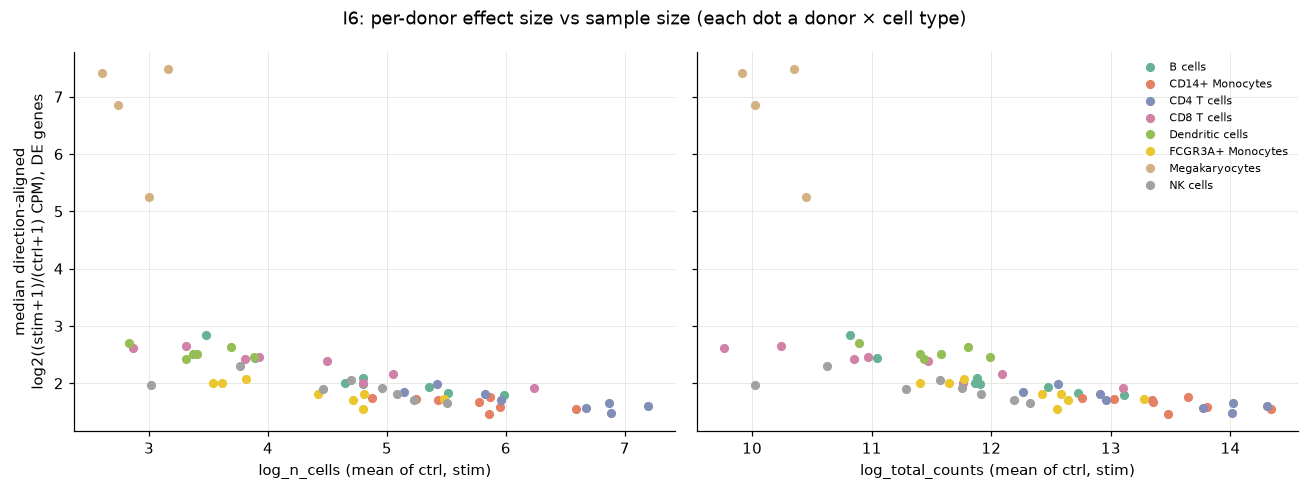

In [13]:
i6 = v.i6_effects(counts, samples, de)
save(i6, "i6_effects")
display(i6.groupby("cell_type")[["n_de", "median_log2_ratio_aligned", "median_log2_ratio"]].agg(["min", "max"]).loc[STACK_ORDER].round(2))
i6_cor = pd.DataFrame([{"cell_type": ct, "y": y, "x": x, "n_donors": len(g), "spearman": stats.spearmanr(g[x], g[y]).statistic}
                       for ct, g in i6.groupby("cell_type") for y in ["median_log2_ratio_aligned", "median_log2_ratio"]
                       for x in ["log_n_cells", "log_total_counts"]])
display(i6_cor.pivot_table(index="cell_type", columns=["y", "x"], values="spearman").loc[STACK_ORDER].round(2))
save(i6_cor, "i6_spearman")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, x in zip(axes, ["log_n_cells", "log_total_counts"]):
    for ct, g in i6.groupby("cell_type"):
        ax.plot(g[x], g["median_log2_ratio_aligned"], "o", c=CT_COLORS[ct], label=ct, ms=5)
    ax.set(xlabel=x + " (mean of ctrl, stim)")
axes[0].set_ylabel("median direction-aligned\nlog2((stim+1)/(ctrl+1) CPM), DE genes"); axes[1].legend(fontsize=7, frameon=False, bbox_to_anchor=(1, 1))
fig.suptitle("I6: per-donor effect size vs sample size (each dot a donor × cell type)")
plt.tight_layout(); fig.savefig(FIG / "m2b_i6.png", dpi=200, bbox_inches="tight"); plt.show()